In [1]:
# Program 1: Uber Ride Fare Prediction
# Dataset: https://www.kaggle.com/datasets/yasserh/uber-fares-dataset (uber.csv)

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings('ignore')
%matplotlib inline

In [2]:
# Load dataset
df = pd.read_csv('uber.csv')
print(f"Original shape: {df.shape}")
df.head()

Original shape: (200000, 9)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [3]:
# Pre-processing & Feature Extraction
df = df.drop(['Unnamed: 0', 'key'], axis=1, errors='ignore')
df = df.dropna()

df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'], errors='coerce')
df = df.dropna(subset=['pickup_datetime'])
df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year
df['day_of_week'] = df['pickup_datetime'].dt.dayofweek
df = df.drop('pickup_datetime', axis=1)

# Haversine distance
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
    return 2.0 * R * np.arcsin(np.sqrt(a))

df['distance_km'] = haversine(
    df['pickup_latitude'], df['pickup_longitude'],
    df['dropoff_latitude'], df['dropoff_longitude']
)
df.head()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,day_of_week,distance_km
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,2015,3,1.683323
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2009,4,2.457590
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,2009,0,5.036377
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,2009,4,1.661683
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,2014,3,4.475450


In [4]:
# Outlier Removal
df = df[(df['fare_amount'] > 0) & (df['fare_amount'] < 200)]
df = df[(df['distance_km'] > 0) & (df['distance_km'] < 200)]
df = df[(df['passenger_count'] > 0) & (df['passenger_count'] <= 6)]
df = df[(df['pickup_latitude'].between(40.0, 42.0)) &
        (df['pickup_longitude'].between(-75.0, -72.0)) &
        (df['dropoff_latitude'].between(40.0, 42.0)) &
        (df['dropoff_longitude'].between(-75.0, -72.0))]
print(f"Cleaned shape: {df.shape}")

Cleaned shape: (193059, 12)


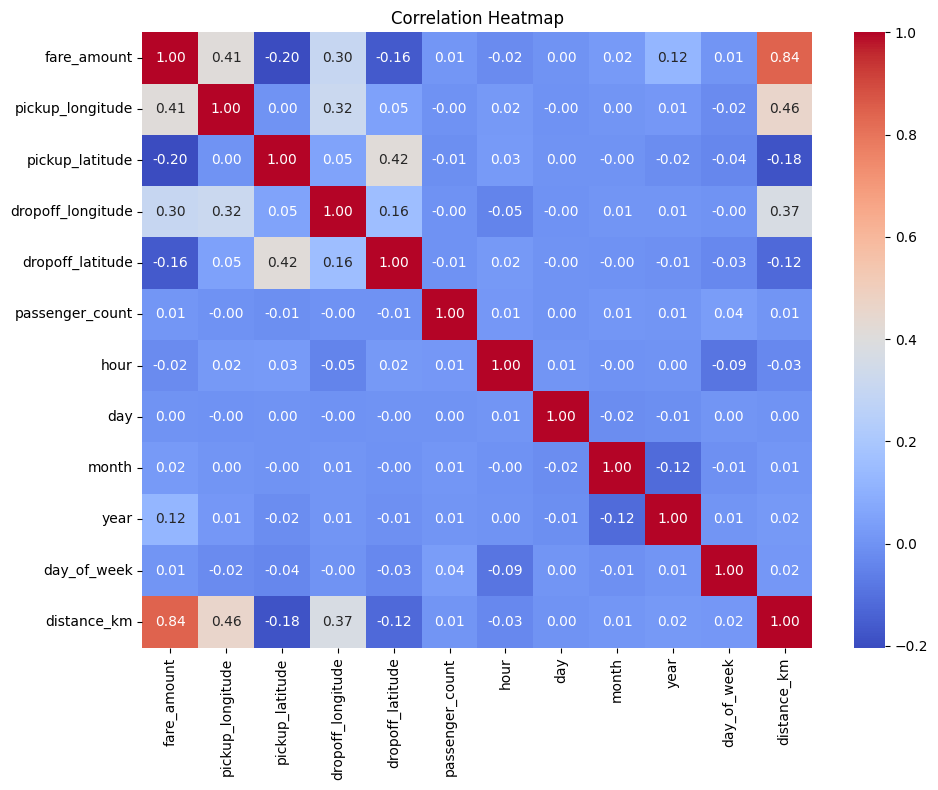

In [5]:
# Correlation Heatmap
numeric_cols = df.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(10, 8))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [6]:
# Model Training & Evaluation
features = ['distance_km', 'passenger_count', 'hour', 'day', 'month', 'year', 'day_of_week']
X = df[features]
y = df['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

# Random Forest
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

print("Linear Regression:")
print(f"  R2 Score : {r2_score(y_test, lr_pred):.4f}")
print(f"  RMSE     : {np.sqrt(mean_squared_error(y_test, lr_pred)):.4f}")
print(f"  MAE      : {mean_absolute_error(y_test, lr_pred):.4f}")

print("\nRandom Forest:")
print(f"  R2 Score : {r2_score(y_test, rf_pred):.4f}")
print(f"  RMSE     : {np.sqrt(mean_squared_error(y_test, rf_pred)):.4f}")
print(f"  MAE      : {mean_absolute_error(y_test, rf_pred):.4f}")

Linear Regression:
  R2 Score : 0.7477
  RMSE     : 4.8056
  MAE      : 2.3324

Random Forest:
  R2 Score : 0.8075
  RMSE     : 4.1973
  MAE      : 2.1638
